<a href="https://colab.research.google.com/github/minato1204love-TTP/Khang_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment_(Assignment_4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Load dataset
data = pd.read_csv('car_purchase_data.csv')

# Preview dataset
display(data.head())
print('Shape:', data.shape)


,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


Shape: (400, 5)


### Step 2: Split features and target

In [3]:

# Features and target
X = data[['Age', 'Salary']]
y = data['Purchased']

print('X shape:', X.shape)
print('y distribution:\n', y.value_counts())


X shape: (400, 2)
y distribution:
 Purchased
0    257
1    143
Name: count, dtype: int64


### Step 3: Train/Test Split

In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0, stratify=y
)

print('Train size:', X_train.shape[0],
      ' Test size:', X_test.shape[0])


Train size: 320  Test size: 80


### Step 4: Feature Scaling

In [5]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print('Scaling complete.')


Scaling complete.


### Step 5: Train Logistic Regression Model

In [6]:

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV

# Build a logistic regression model
pipeline = make_pipeline(
    PolynomialFeatures(include_bias=False),
    LogisticRegression(max_iter=5000)
)

# Try different model settings
param_grid = {
    'polynomialfeatures__degree': [1, 2, 3],
    'logisticregression__C': [0.1, 1, 10, 100]
}

# Select settings using training data only
search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring='accuracy'
)

search.fit(X_train, y_train)

model = search.best_estimator_

print('Best parameters:', search.best_params_)
print('Cross-validation accuracy:', search.best_score_)
print('Model trained.')


Best parameters: {'logisticregression__C': 1, 'polynomialfeatures__degree': 2}
Cross-validation accuracy: 0.903125
Model trained.


### Step 6: Predict and Evaluate

In [7]:

# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
acc = accuracy_score(y_test, y_pred)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display evaluation results
print('Accuracy:', acc)
print('\nConfusion Matrix:\n', cm)
print('\nClassification Report:\n',
      classification_report(y_test, y_pred))


Accuracy: 0.9125

Confusion Matrix:
 [[47  4]
 [ 3 26]]

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.92      0.93        51
           1       0.87      0.90      0.88        29

    accuracy                           0.91        80
   macro avg       0.90      0.91      0.91        80
weighted avg       0.91      0.91      0.91        80



In [8]:

# Examine purchase rates by age and salary
print(data.groupby('Purchased')[['Age', 'Salary']].mean())


                 Age        Salary
Purchased                         
0          32.793774  60544.747082
1          46.391608  86272.727273


### Step 7: Visualization of Decision Regions

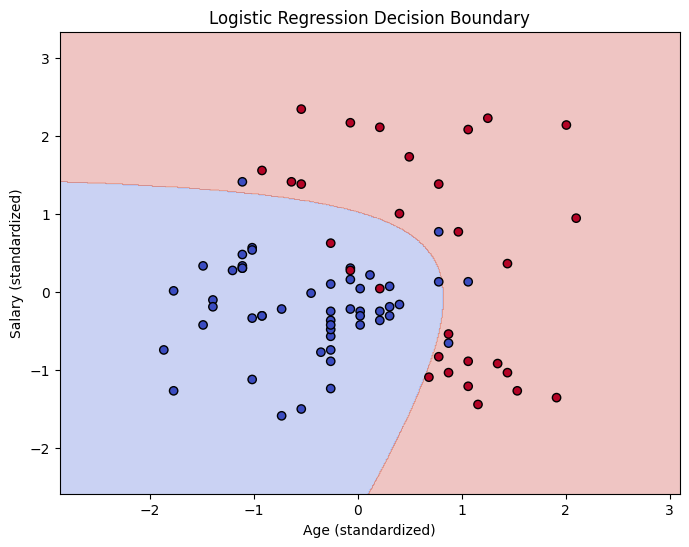

In [9]:

# Use the scaled test data
X_set, y_set = X_test, y_test.values

# Define the plot boundaries
x1_min, x1_max = X_set[:, 0].min() - 1, X_set[:, 0].max() + 1
x2_min, x2_max = X_set[:, 1].min() - 1, X_set[:, 1].max() + 1

# Create a grid
X1, X2 = np.meshgrid(
    np.arange(x1_min, x1_max, 0.01),
    np.arange(x2_min, x2_max, 0.01)
)

# Predict each point on the grid
Z = model.predict(
    np.array([X1.ravel(), X2.ravel()]).T
)
Z = Z.reshape(X1.shape)

# Visualize the decision regions
plt.figure(figsize=(8, 6))
plt.contourf(X1, X2, Z, alpha=0.3, cmap='coolwarm')

plt.scatter(
    X_set[:, 0],
    X_set[:, 1],
    c=y_set,
    edgecolor='k',
    cmap='coolwarm'
)

plt.title('Logistic Regression Decision Boundary')
plt.xlabel('Age (standardized)')
plt.ylabel('Salary (standardized)')
plt.show()


## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

**1. Logistic regression outputs probabilities — why can it still be used for classification?**

Logistic regression can be used for classification because it converts predicted probabilities into categories using a threshold. For example, if the probability is 0.5 or higher, the model predicts that the customer will purchase a car (1). Otherwise, it predicts that the customer will not purchase a car (0).

**2. Based on your model, which customers are more likely to purchase a car?**

The model uses Age and Salary to predict whether customers will purchase a car. The improved model can identify more complex patterns between these features and purchasing decisions. It achieved 91.25% accuracy, correctly predicting 73 out of 80 customers. It also correctly identified 26 out of 29 actual purchasers. This suggests that using polynomial features improved the model's ability to predict car purchases.

**3. What factors might cause low accuracy in this task?**

Low accuracy could result from limited training data, missing important features, or overlapping patterns between customers who purchase cars and those who do not. Age and Salary alone may not provide enough information to accurately predict every customer's purchasing decision.

**4. Propose additional features or preprocessing steps that could improve accuracy.**

To improve accuracy, I would include additional features such as employment status, credit score, marital status, and previous car ownership. I would also check for outliers, missing values, and class imbalance. Testing different model settings and using cross-validation could help improve the model's performance.

**Objective Understanding**

The goal of this assignment is to use logistic regression to predict whether a customer will purchase a car based on their Age and Salary. Logistic regression is appropriate because the target variable, Purchased, has two possible outcomes: 0 (No) and 1 (Yes). Unlike linear regression, which predicts continuous values, logistic regression estimates probabilities that can be converted into classifications. This helps identify patterns in customer purchasing behavior.